# Noise testing: training on CIFAR-10 + SVHN noise

**Question:** how does each uncertainty method hold up when the training set is contaminated with unrelated images?

- **`train_aug`** = the CIFAR-10 training split (36,000 images) plus SVHN digit images, each SVHN image given a **uniformly random CIFAR label 0–9**.
- Train any model (Baseline, MC Dropout, Laplace, SNGP, Deep Ensemble) on `train_aug` with `train_with_noise(model, ...)`.
- Test on the **original clean CIFAR-10 test split**, then wrap the model in the **common conformal layer** with `evaluate_conformal(model, ...)`.

Setup details:
- **Split:** the repo's stratified 60/20/20 split (split seed 0), the same one every model notebook uses: train 36k (+ SVHN), test 12k, calibration 12k. Test and calibration data are identical for every run.
- **Conformal layer:** randomized APS from `models/deep_ensembles/conformal_fixed.py`, plus LAC and Mondrian (per-class) variants. The original deterministic APS isn't used; `CONFORMAL_AUDIT.md` explains why.
- **Seeds:** `seed` controls weight init, batch order, augmentation and eval-time sampling. `noise_seed` (defaults to `seed`) controls which SVHN images are drawn and the labels they get.
- Code lives in `pipeline/`. Checkpoints go to `models/noise_testing/` (git-ignored) and are reused, so re-running a cell only trains runs that don't have a checkpoint yet. Results go to `results/noise_testing/`.

Run this notebook from the **repo root**.

In [ ]:
# Setup: Register all necessary imports and packages

from IPython.display import Markdown, display
import numpy as np

from pipeline import (Baseline, MCDropout, LaplaceLL, SNGP, DeepEnsemble,
                      build_train_aug, train_with_noise, evaluate_conformal,
                      run_experiment, compare, summarize)
from pipeline.evaluate import to_markdown
import common
print("device:", common.DEVICE)

device: cuda


In [ ]:
# ------------------------------- Config ---------------------------------------
SMOKE = True            # True: tiny subsets + 1 epoch to check everything runs end-to-end
EPOCHS = 1 if SMOKE else common.EPOCHS        # 40 = the shared recipe
NOISE_RATIOS = [0.0, 0.25]   # SVHN images added, as a fraction of the 36k CIFAR train images
SEEDS = [0, 1, 2]
ALPHA = 0.1             # target coverage 90%
N_RESPLITS = 0 if SMOKE else 100   # extra cal/test re-splits for the coverage mean +- std

# Model factories: a class or zero-arg callable that returns an adapter
MODELS = {
    "baseline":      Baseline,
    "mc_dropout":    lambda: MCDropout(p=0.5, T=50),
    "laplace":       LaplaceLL,
    "sngp":          lambda: SNGP(norm_bound=6.0),
    "deep_ensemble": lambda: DeepEnsemble(n=5),
}

# We lookup models using models[model] for model in RUN_MODELS (or some similar code)
RUN_MODELS = ["baseline", "mc_dropout", "laplace", "sngp", "deep_ensemble"]

## 1. Build and inspect `train_aug`

In [ ]:
# Calls build_train_aug, which creates a list of noise_ratio * n SVHN images,
#		each one labelled with a random CIFAR-10 label.

data = build_train_aug(noise_ratio=0.25, seed=0)

y = data["train_aug"].labels
print(f"train_aug: {len(y)} images = {data['n_cifar']} CIFAR + {data['n_svhn']} SVHN")
print(f"test: {len(data['test'])}   cal: {len(data['cal'])}")
print("label counts, CIFAR part:", np.bincount(y[~data['is_noise']]))  # '~' is numpy's NOT operator.
print("label counts, SVHN part :", np.bincount(y[data['is_noise']]))

NameError: name 'build_train_aug' is not defined

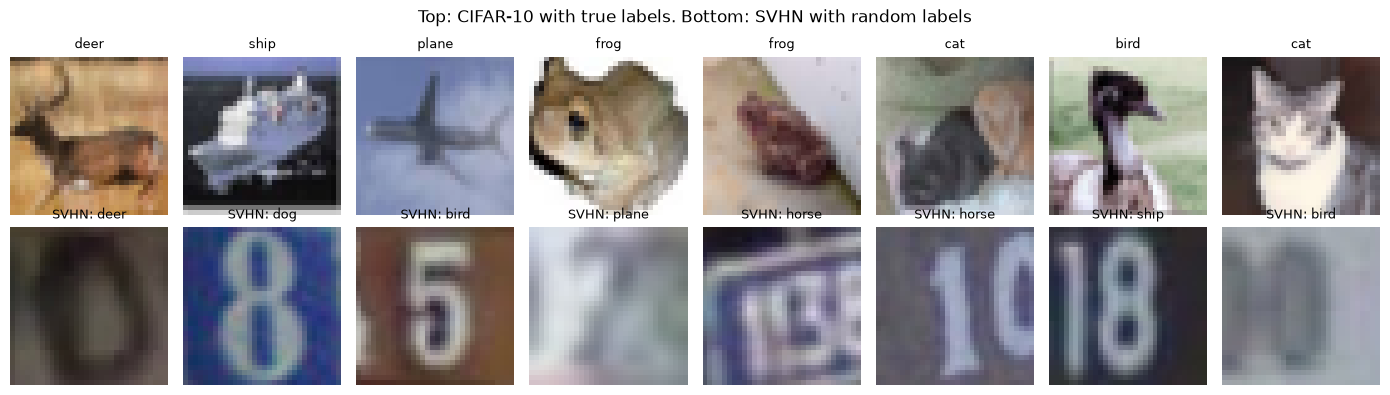

In [ ]:
import matplotlib.pyplot as plt

CLASSES = ["plane", "car", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
imgs = data["train_aug"].images
rng = np.random.RandomState(0)

# Display randomized images from the train_aug. Picks 8 CIFAR and SVHN parts, respectively.
pick = np.r_[rng.choice(np.where(~data["is_noise"])[0], 8, replace=False),
             rng.choice(np.where(data["is_noise"])[0], 8, replace=False)]
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for ax, i in zip(axes.ravel(), pick):
    ax.imshow(imgs[i]); ax.axis("off")
    ax.set_title(("SVHN: " if data["is_noise"][i] else "") + CLASSES[y[i]], fontsize=9)
plt.suptitle("Top: CIFAR-10 with true labels. Bottom: SVHN with random labels")
plt.tight_layout(); plt.show()

## 2. Single run: `train_with_noise` → `evaluate_conformal`

`train_with_noise(model, noise_ratio, seed, ...)` builds `train_aug`, (re)initialises the model from `seed`, trains it with the shared recipe (SGD + Nesterov, lr 0.1, cosine schedule, weight decay 5e-4), and runs any post-hoc step: the Laplace fit or the SNGP covariance. That step uses the un-augmented `train_aug`, **including the noisy SVHN points**, because they are part of the training data. The training log reports accuracy separately on the CIFAR and SVHN parts of each batch. SVHN accuracy rising above 0.1 means the network is memorising the random labels.

In [ ]:
# A brief test to see if our pipeline works
#   Train the baseline model with a .25 noise ratio

run = train_with_noise(Baseline(), noise_ratio=0.25, seed=0, epochs=EPOCHS, smoke=SMOKE)

# Send the model through the conformal layer.
res = evaluate_conformal(run["model"], run["loaders"]["cal"], run["loaders"]["test"],
                         alpha=ALPHA, seed=0, n_resplits=N_RESPLITS,
                         tag=run["tag"], config=run["config"])

c = res["conformal"]
print(f"accuracy {res['accuracy']:.4f}  NLL {res['nll']:.4f}  ECE {res['ece']:.4f}  Brier {res['brier']:.4f}")
for s in ("aps_rand", "lac"):
    print(f"{s:9s} coverage {c[s]['coverage']:.4f}  avg set size {c[s]['avg_set_size']:.3f}  "
          f"empty {c[s]['frac_empty']:.3f}  singletons {c[s]['singleton_frac']:.3f}")
print("Mondrian per-class coverage:", np.round(c["mondrian_aps_rand"]["per_class_coverage"], 3))
print("coverage by set size (aps_rand):", {k: round(v, 3) for k, v in c["aps_rand"]["coverage_by_set_size"].items()})

[baseline_noise0.25_seed0_ep1_smoke] epoch   1/1  loss=2.3027 acc=0.1333 (cifar 0.1441, svhn 0.0902)  cal_loss=3.3094 cal_acc=0.1405  0.0min
accuracy 0.1310  NLL 3.2884  ECE 0.3414  Brier 1.0780
aps_rand  coverage 0.9035  avg set size 7.559  empty 0.000  singletons 0.000
lac       coverage 0.9105  avg set size 7.515  empty 0.000  singletons 0.000
Mondrian per-class coverage: [0.877 0.817 0.903 0.959 0.901 0.898 0.883 0.917 0.938 0.937]
coverage by set size (aps_rand): {2: 0.438, 3: 0.743, 4: 0.854, 5: 0.801, 6: 0.802, 7: 0.721, 8: 0.827, 9: 0.929, 10: 1.0}


## 3. Multi-seed sweep over models and noise levels

`run_experiment(factory, NOISE_RATIOS, SEEDS)` trains and evaluates one run per (noise ratio, seed). Runs that already have a checkpoint are loaded rather than retrained, so you can add seeds or noise levels later.

**Cost:** about 100 minutes per network for 40 CPU epochs (much less on a GPU). The ensemble trains 5 networks per run.

In [ ]:
# Runs our Novel Contribution 1 experiment (noise injection)
#   on each of our four models (SNGP, MC Dropout, Deep Ensembles, Laplace)

results = []
for name in RUN_MODELS:
    print(f"==================== {name}")

    # Run the full experiment pipeline (train + test + conformal layer)
    #   on each model in RUN_MODELS, on every (noise_ratio, seed) combination.
    
    results += run_experiment(MODELS[name], NOISE_RATIOS, SEEDS, alpha=ALPHA,
                              n_resplits=N_RESPLITS, smoke=SMOKE, epochs=EPOCHS)

NameError: name 'RUN_MODELS' is not defined

In [8]:
rows = compare(results)   # also writes results/noise_testing/results.json
display(Markdown(to_markdown(rows)))

| model | noise_ratio | n_svhn | seed | accuracy | nll | ece | brier | aps_coverage | aps_set_size | aps_frac_empty | lac_coverage | lac_set_size | mondrian_min_class_cov |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| baseline | 0.0000 | 0 | 0 | 0.1595 | 3.0466 | 0.4400 | 1.1341 | 0.8810 | 6.6210 | 0.0000 | 0.8765 | 6.5385 | 0.8409 |
| baseline | 0.0000 | 0 | 1 | 0.1070 | 5.0309 | 0.7042 | 1.4792 | 0.8965 | 8.1905 | 0.0000 | 0.9000 | 8.2005 | 0.8341 |
| baseline | 0.0000 | 0 | 2 | 0.1640 | 2.7577 | 0.2273 | 0.9762 | 0.9015 | 7.5760 | 0.0000 | 0.9030 | 7.5480 | 0.8455 |
| baseline | 0.2500 | 9000 | 0 | 0.1310 | 3.2884 | 0.3414 | 1.0780 | 0.9035 | 7.5585 | 0.0000 | 0.9105 | 7.5150 | 0.8173 |
| baseline | 0.2500 | 9000 | 1 | 0.1050 | 6.8595 | 0.6010 | 1.3396 | 0.8925 | 8.1100 | 0.0000 | 0.8945 | 8.1100 | 0.8750 |
| baseline | 0.2500 | 9000 | 2 | 0.1810 | 2.3670 | 0.1737 | 0.9202 | 0.8915 | 7.1475 | 0.0000 | 0.8880 | 6.9710 | 0.7818 |
| mc_dropout | 0.0000 | 0 | 0 | 0.1320 | 2.6129 | 0.2761 | 0.9799 | 0.9145 | 8.4010 | 0.0000 | 0.9135 | 8.2425 | 0.8539 |
| mc_dropout | 0.0000 | 0 | 1 | 0.1290 | 3.6239 | 0.2846 | 1.0685 | 0.8980 | 7.9990 | 0.0000 | 0.8985 | 7.9855 | 0.8325 |
| mc_dropout | 0.0000 | 0 | 2 | 0.1725 | 2.4693 | 0.1593 | 0.9296 | 0.8975 | 7.9615 | 0.0000 | 0.8910 | 7.7095 | 0.8325 |
| mc_dropout | 0.2500 | 9000 | 0 | 0.1665 | 2.4481 | 0.1186 | 0.9155 | 0.9230 | 8.6175 | 0.0000 | 0.9175 | 8.5800 | 0.8719 |
| mc_dropout | 0.2500 | 9000 | 1 | 0.1300 | 3.7876 | 0.2305 | 1.0078 | 0.9015 | 8.1750 | 0.0000 | 0.9015 | 8.1300 | 0.8523 |
| mc_dropout | 0.2500 | 9000 | 2 | 0.1510 | 3.4033 | 0.3631 | 1.0945 | 0.8965 | 7.8720 | 0.0000 | 0.8970 | 7.8450 | 0.8325 |
| laplace | 0.0000 | 0 | 0 | 0.1090 | 3.6415 | 0.4716 | 1.2020 | 0.9040 | 8.6005 | 0.0000 | 0.8835 | 8.2220 | 0.8466 |
| laplace | 0.0000 | 0 | 1 | 0.1440 | 2.7556 | 0.2512 | 0.9918 | 0.9005 | 8.0780 | 0.0000 | 0.8965 | 7.8795 | 0.8325 |
| laplace | 0.0000 | 0 | 2 | 0.1770 | 2.4559 | 0.1530 | 0.9101 | 0.8915 | 7.2575 | 0.0000 | 0.9035 | 7.3230 | 0.8318 |
| laplace | 0.2500 | 9000 | 0 | 0.1340 | 2.6142 | 0.1834 | 0.9554 | 0.8885 | 8.7710 | 0.0000 | 0.8930 | 8.6890 | 0.8376 |
| laplace | 0.2500 | 9000 | 1 | 0.1465 | 2.7474 | 0.2107 | 0.9616 | 0.9030 | 7.6255 | 0.0000 | 0.9080 | 7.5540 | 0.8777 |
| laplace | 0.2500 | 9000 | 2 | 0.1645 | 2.8234 | 0.2641 | 1.0154 | 0.8955 | 7.2375 | 0.0000 | 0.9010 | 7.2795 | 0.7818 |
| sngp | 0.0000 | 0 | 0 | 0.0950 | 2.3364 | 0.0524 | 0.9068 | 0.9015 | 9.0125 | 0.0000 | 0.9020 | 9.0265 | 0.8705 |
| sngp | 0.0000 | 0 | 1 | 0.0955 | 2.3236 | 0.0380 | 0.9045 | 0.9030 | 8.9525 | 0.0000 | 0.9035 | 9.0075 | 0.8966 |
| sngp | 0.0000 | 0 | 2 | 0.1140 | 2.3409 | 0.0368 | 0.9075 | 0.9015 | 9.0570 | 0.0000 | 0.8965 | 8.9980 | 0.8775 |
| sngp | 0.2500 | 9000 | 0 | 0.0950 | 2.3352 | 0.0514 | 0.9066 | 0.8970 | 8.9945 | 0.0000 | 0.9015 | 9.0290 | 0.8723 |
| sngp | 0.2500 | 9000 | 1 | 0.0885 | 2.3229 | 0.0448 | 0.9044 | 0.9070 | 8.9510 | 0.0000 | 0.8985 | 8.9640 | 0.8909 |
| sngp | 0.2500 | 9000 | 2 | 0.1160 | 2.3343 | 0.0266 | 0.9062 | 0.8995 | 9.0185 | 0.0000 | 0.8880 | 8.9725 | 0.8705 |
| deep_ensemble | 0.0000 | 0 | 0 | 0.2225 | 2.0360 | 0.0361 | 0.8411 | 0.8890 | 6.6000 | 0.0000 | 0.8895 | 6.5645 | 0.8227 |
| deep_ensemble | 0.0000 | 0 | 1 | 0.1600 | 2.8460 | 0.2148 | 0.9713 | 0.9010 | 7.9015 | 0.0000 | 0.9045 | 7.7715 | 0.8523 |
| deep_ensemble | 0.0000 | 0 | 2 | 0.1275 | 2.3307 | 0.1951 | 0.9146 | 0.8990 | 7.5120 | 0.0000 | 0.9065 | 7.4710 | 0.8318 |
| deep_ensemble | 0.2500 | 9000 | 0 | 0.2215 | 2.3276 | 0.0431 | 0.8799 | 0.9000 | 7.9285 | 0.0000 | 0.9030 | 7.9065 | 0.8522 |
| deep_ensemble | 0.2500 | 9000 | 1 | 0.1575 | 2.5625 | 0.1736 | 0.9397 | 0.9080 | 7.5330 | 0.0000 | 0.9150 | 7.4370 | 0.8636 |
| deep_ensemble | 0.2500 | 9000 | 2 | 0.1385 | 2.2583 | 0.1682 | 0.9006 | 0.8995 | 7.2480 | 0.0000 | 0.9000 | 7.1825 | 0.8364 |

## 4. Clean vs noisy (mean ± std over seeds)

In [9]:
summary = summarize(rows)
keys = ["model", "noise_ratio", "n_seeds", "accuracy", "nll", "ece", "brier",
        "aps_coverage", "aps_set_size", "lac_coverage", "lac_set_size", "mondrian_min_class_cov"]
display(Markdown(to_markdown(summary, keys)))

| model | noise_ratio | n_seeds | accuracy | nll | ece | brier | aps_coverage | aps_set_size | lac_coverage | lac_set_size | mondrian_min_class_cov |
|---|---|---|---|---|---|---|---|---|---|---|---|
| baseline | 0.0000 | 3 | 0.1435 ± 0.0317 | 3.6117 ± 1.2375 | 0.4572 ± 0.2389 | 1.1965 ± 0.2572 | 0.8930 ± 0.0107 | 7.4625 ± 0.7909 | 0.8932 ± 0.0145 | 7.4290 ± 0.8374 | 0.8402 ± 0.0057 |
| baseline | 0.2500 | 3 | 0.1390 ± 0.0386 | 4.1716 ± 2.3729 | 0.3720 ± 0.2153 | 1.1126 ± 0.2118 | 0.8958 ± 0.0067 | 7.6053 ± 0.4830 | 0.8977 ± 0.0116 | 7.5320 ± 0.5697 | 0.8247 ± 0.0470 |
| mc_dropout | 0.0000 | 3 | 0.1445 ± 0.0243 | 2.9021 ± 0.6293 | 0.2400 ± 0.0700 | 0.9927 ± 0.0703 | 0.9033 ± 0.0097 | 8.1205 ± 0.2436 | 0.9010 ± 0.0115 | 7.9792 ± 0.2666 | 0.8396 ± 0.0123 |
| mc_dropout | 0.2500 | 3 | 0.1492 ± 0.0183 | 3.2130 ± 0.6897 | 0.2374 ± 0.1224 | 1.0060 ± 0.0895 | 0.9070 ± 0.0141 | 8.2215 ± 0.3749 | 0.9053 ± 0.0108 | 8.1850 ± 0.3706 | 0.8522 ± 0.0197 |
| laplace | 0.0000 | 3 | 0.1433 ± 0.0340 | 2.9510 ± 0.6165 | 0.2919 ± 0.1631 | 1.0346 ± 0.1506 | 0.8987 ± 0.0064 | 7.9787 ± 0.6770 | 0.8945 ± 0.0101 | 7.8082 ± 0.4537 | 0.8370 ± 0.0083 |
| laplace | 0.2500 | 3 | 0.1483 ± 0.0153 | 2.7283 ± 0.1059 | 0.2194 ± 0.0411 | 0.9775 ± 0.0330 | 0.8957 ± 0.0073 | 7.8780 ± 0.7973 | 0.9007 ± 0.0075 | 7.8408 ± 0.7472 | 0.8323 ± 0.0481 |
| sngp | 0.0000 | 3 | 0.1015 ± 0.0108 | 2.3336 ± 0.0090 | 0.0424 ± 0.0087 | 0.9063 ± 0.0016 | 0.9020 ± 0.0009 | 9.0073 ± 0.0524 | 0.9007 ± 0.0037 | 9.0107 ± 0.0145 | 0.8815 ± 0.0135 |
| sngp | 0.2500 | 3 | 0.0998 ± 0.0144 | 2.3308 ± 0.0068 | 0.0409 ± 0.0129 | 0.9057 ± 0.0012 | 0.9012 ± 0.0052 | 8.9880 ± 0.0342 | 0.8960 ± 0.0071 | 8.9885 ± 0.0353 | 0.8779 ± 0.0113 |
| deep_ensemble | 0.0000 | 3 | 0.1700 ± 0.0483 | 2.4042 ± 0.4100 | 0.1487 ± 0.0980 | 0.9090 ± 0.0653 | 0.8963 ± 0.0064 | 7.3378 ± 0.6680 | 0.9002 ± 0.0093 | 7.2690 ± 0.6283 | 0.8356 ± 0.0152 |
| deep_ensemble | 0.2500 | 3 | 0.1725 ± 0.0435 | 2.3828 ± 0.1594 | 0.1283 ± 0.0739 | 0.9067 ± 0.0303 | 0.9025 ± 0.0048 | 7.5698 ± 0.3417 | 0.9060 ± 0.0079 | 7.5087 ± 0.3673 | 0.8507 ± 0.0137 |

In [10]:
# Change relative to the clean (noise_ratio = 0) run of the same model
delta_keys = ["accuracy", "ece", "nll", "aps_coverage", "aps_set_size", "lac_set_size"]
clean = {s["model"]: s for s in summary if s["noise_ratio"] == 0.0}
deltas = [{"model": s["model"], "noise_ratio": s["noise_ratio"],
           **{f"Δ{k}": s[k] - clean[s["model"]][k] for k in delta_keys}}
          for s in summary if s["noise_ratio"] != 0.0 and s["model"] in clean]
display(Markdown(to_markdown(deltas)))

| model | noise_ratio | Δaccuracy | Δece | Δnll | Δaps_coverage | Δaps_set_size | Δlac_set_size |
|---|---|---|---|---|---|---|---|
| baseline | 0.2500 | -0.0045 | -0.0851 | 0.5599 | 0.0028 | 0.1428 | 0.1030 |
| mc_dropout | 0.2500 | 0.0047 | -0.0026 | 0.3109 | 0.0037 | 0.1010 | 0.2058 |
| laplace | 0.2500 | 0.0050 | -0.0725 | -0.2227 | -0.0030 | -0.1007 | 0.0327 |
| sngp | 0.2500 | -0.0017 | -0.0015 | -0.0029 | -0.0008 | -0.0193 | -0.0222 |
| deep_ensemble | 0.2500 | 0.0025 | -0.0204 | -0.0214 | 0.0062 | 0.2320 | 0.2397 |

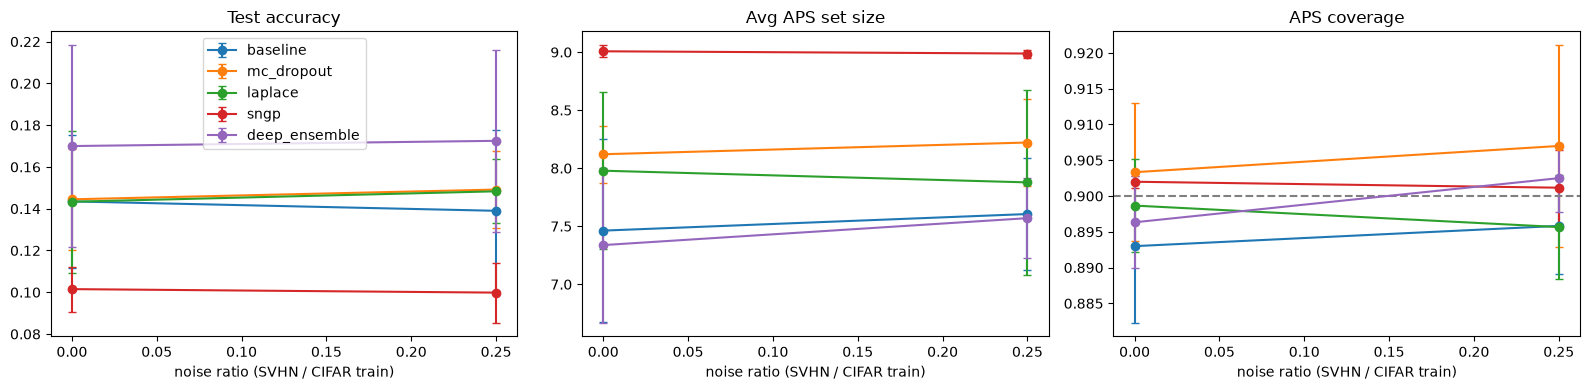

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for m in dict.fromkeys(s["model"] for s in summary):
    g = sorted((s for s in summary if s["model"] == m), key=lambda s: s["noise_ratio"])
    x = [s["noise_ratio"] for s in g]
    for ax, k in zip(axes, ["accuracy", "aps_set_size", "aps_coverage"]):
        ax.errorbar(x, [s[k] for s in g], yerr=[s[k + "_std"] for s in g], marker="o", capsize=3, label=m)
axes[2].axhline(1 - ALPHA, ls="--", c="gray", label="target")
for ax, t in zip(axes, ["Test accuracy", "Avg APS set size", "APS coverage"]):
    ax.set_title(t); ax.set_xlabel("noise ratio (SVHN / CIFAR train)")
axes[0].legend(); plt.tight_layout(); plt.show()

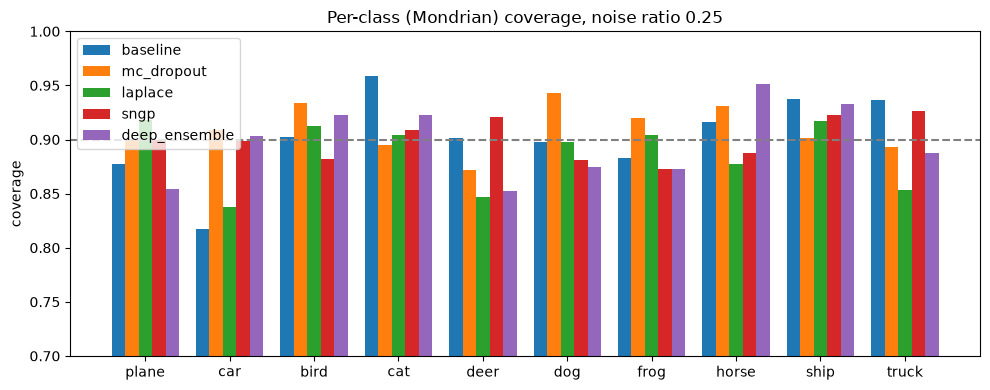

In [12]:
# Mondrian per-class coverage at the highest noise level (first seed)
hi = max(NOISE_RATIOS)
fig, ax = plt.subplots(figsize=(10, 4))
sel = [r for r in results if r.get("noise_ratio") == hi and r.get("seed") == SEEDS[0]]
w = 0.8 / max(len(sel), 1)
for j, r in enumerate(sel):
    ax.bar(np.arange(10) + j * w, r["conformal"]["mondrian_aps_rand"]["per_class_coverage"], w, label=r["model"])
ax.axhline(1 - ALPHA, ls="--", c="gray")
ax.set_xticks(np.arange(10) + 0.4 - w / 2); ax.set_xticklabels(CLASSES)
ax.set_ylim(0.7, 1.0); ax.set_ylabel("coverage"); ax.set_title(f"Per-class (Mondrian) coverage, noise ratio {hi}")
ax.legend(); plt.tight_layout(); plt.show()

## Notes
- Split-conformal coverage is guaranteed to be about 1 − α (marginally, over the cal/test split) **whatever the model quality**, so noise should mostly show up as **larger prediction sets**, lower accuracy and worse calibration, not as lost coverage. A coverage far from 0.90 indicates a bug. Mondrian per-class coverage and the size-stratified coverage in `res["conformal"]` show whether coverage is uneven across classes or set sizes.
- Single-split coverage varies by about ±0.4% by chance. Set `N_RESPLITS = 100` to get `res["conformal"][score]["resplit"]` (mean ± std over random cal/test re-splits).
- Probabilities for every run are saved to `results/noise_testing/{tag}.npz`. Use `pipeline.evaluate.conformal_metrics(...)` on them to try another α without running inference again.
- For a given `seed`, results should be reproducible on CPU. On GPU, pass `deterministic=True` to `train_with_noise` for cuDNN determinism.